# Data Exploration

Here are some basic steps we can take when confronted with a dataset. We don't always go through all of these in order, but if we spend enough time with a dataset, we usually end up returning to all of these, often more than once.

1. Get oriented: shape (how many rows/columns/participants/etc.), dtypes, missing values, descriptive statistics.
2. Look at each variable: distributions, outliers, categorical breakdowns.
3. Investigate relationships: correlations, groupings, counts.
4. Transform & re-visualize: encode, aggregate, drop, pivot; look again.
5. Form mini hypotheses and questions: "Why is the data in column X skewed?" / "Why might columns Y and Z be correlated?"
6. Repeat as you refine your questions.

## Adult Language Learning Profile

These data come from a (surprise!) Dutch study (Schepens et al, 2020), that collected scores by adult language learners on a test of spoken Dutch ("STEX"). 

They also collected data on the learners such as their education level, their native language, their country of birth, length of time in the Netherlands, and the similarity of their native language to Dutch, etc. Below you can see all the types of data they collected, together with the abbreviations in the column headers.


The columns of data are:  

- "L1" - The first language of the learner
- "C" - The country of birth
- "L1L2" - The combination of first and best additional language besides Dutch
- "L2" - The best additional language besides Dutch
- "AaA" - Age at Arrival in the Netherlands in years (starting date of residence)
- "LoR" - Length of residence in the Netherlands in years
- "Edu.day" - Duration of daily education (1 low, 2 middle, 3 high, 4 very high). From 1992 until 2006, learners' education has been measured by means of a side-by-side matrix question in a learner's questionnaire. Learners were asked to mark which type of education they have had (elementary, secondary, or tertiary schooling) by means of filling in for how many years they have been enrolled, in which country, and whether or not they have graduated. Based on this information we were able to estimate how many years learners have had education on a daily basis from six years of age onwards. Since 2006, the question about learners' education has been altered and it is asked directly how many years learners have had formal education on a daily basis from six years of age onwards. Possible answering categories are: 1) 0 thru 5 years; 2) 6 thru 10 years; 3) 11 thru 15 years; 4) 16 years or more. The answers have been merged into the categorical answer.
- "Sex" - Gender
- "Family" - Language Family
- "ISO639.3" - Language ID code according to Ethnologue
- "Enroll" - Proportion of school-aged youth enrolled in secondary education according to the World Bank. The World Bank reports on education data in a wide number of countries around the world on a regular basis. We took the gross enrollment rate in secondary schooling per country in the year the learner has arrived in the Netherlands as an indicator for a country's educational accessibility at the time learners have left their country of origin.
- "Speaking" - The STEX test score for speaking proficiency.
- "Dissimilarity_morphological" - Morphological similarity
- "Dissimilarity_lexical" - Lexical similarity
- "Dissimilarity_phonological_new_features" - Phonological similarity (in terms of new features)
- "Dissimilarity_phonological_new_categories" - Phonological similarity (in terms of new sounds)


There are rich opportunities here for investigation. Work your way through some of the steps of data exploration listed above (orientation, investigation, visualization, etc.), and see what you can find.

### References
Schepens, Job, Roeland van Hout, and T. Florian Jaeger. “Big Data Suggest Strong Constraints of Linguistic Similarity on Adult Language Learning.” Cognition 194 (January 1, 2020): 104056. https://doi.org/10.1016/j.cognition.2019.104056. https://zenodo.org/records/2863533#.Y9Y3pNJBwUE

In [118]:
import pandas as pd
import seaborn as sns
import pingouin as pg

url = 'https://raw.githubusercontent.com/ethanweed/ExPsyLing/master/notebooks/data%20exploration/stex.csv'
df = pd.read_csv(url, encoding="cp1252")

In [119]:
# inspect the data
df.head()

,L1,C,L1L2,L2,AaA,LoR,Edu.day,Sex,Family,ISO639.3,Enroll,Speaking,morph,lex,new_feat,new_sounds
0,Afrikaans,SouthAfrica,AfrikaansEnglish,English,25,0,4.0,Female,Indo-European,afr,93,496,NaN,0.010463,NaN,NaN
1,Afrikaans,SouthAfrica,AfrikaansGerman,German,47,2,4.0,Male,Indo-European,afr,93,542,NaN,0.010463,NaN,NaN
2,Afrikaans,SouthAfrica,AfrikaansMonolingual,Monolingual,23,23,3.0,Female,Indo-European,afr,93,585,NaN,0.010463,NaN,NaN
3,Afrikaans,SouthAfrica,AfrikaansMonolingual,Monolingual,42,2,2.0,Female,Indo-European,afr,93,521,NaN,0.010463,NaN,NaN
4,Afrikaans,SouthAfrica,AfrikaansMonolingual,Monolingual,22,19,3.0,Female,Indo-European,afr,93,639,NaN,0.010463,NaN,NaN


In [120]:
# how many rows and columns are in the data?
df.shape

(50235, 16)

In [121]:
# what are the column names in the df?
df.columns

Index(['L1', 'C', 'L1L2', 'L2', 'AaA', 'LoR', 'Edu.day', 'Sex', 'Family',
       'ISO639.3', 'Enroll', 'Speaking', 'morph', 'lex', 'new_feat',
       'new_sounds'],
      dtype='object')

In [122]:
# are there any missing values? How many in each column?
df.isna().sum()

L1               0
C                0
L1L2             0
L2               0
AaA              0
LoR              0
Edu.day          9
Sex              0
Family           0
ISO639.3         0
Enroll           0
Speaking         0
morph         1809
lex              0
new_feat      2016
new_sounds    2016
dtype: int64

In [123]:
# what correlates with what? 
# this is a completely uncritical, non-hypothesis-drive exploration of the data
corr_matrix = df.corr(numeric_only=True)
corr_matrix

,AaA,LoR,Edu.day,Enroll,Speaking,morph,lex,new_feat,new_sounds
AaA,1.000000,-0.188312,0.219943,-0.003540,-0.136891,0.000449,-0.037035,0.059373,0.041512
LoR,-0.188312,1.000000,-0.091627,-0.082751,0.006867,0.076976,0.098486,0.042704,0.055825
Edu.day,0.219943,-0.091627,1.000000,0.027248,0.034630,-0.003215,-0.013897,0.026316,0.031624
Enroll,-0.003540,-0.082751,0.027248,1.000000,0.372622,-0.335544,-0.512117,-0.462783,-0.326703
Speaking,-0.136891,0.006867,0.034630,0.372622,1.000000,-0.323426,-0.437331,-0.325470,-0.326212
morph,0.000449,0.076976,-0.003215,-0.335544,-0.323426,1.000000,0.599171,0.504820,0.396680
lex,-0.037035,0.098486,-0.013897,-0.512117,-0.437331,0.599171,1.000000,0.628929,0.581581
new_feat,0.059373,0.042704,0.026316,-0.462783,-0.325470,0.504820,0.628929,1.000000,0.665045
new_sounds,0.041512,0.055825,0.031624,-0.326703,-0.326212,0.396680,0.581581,0.665045,1.000000


In [124]:
# how many unique participants are there?
# we can also see this from the dataframe shape, since there is one row per participant
# This will of course not always be the case; often we have multiple trial rows per participant.
print('Number of language learners:', len(df))

Number of language learners: 50235


In [125]:
# how many language families are represented in the data, and what are they?
print('Number of language families:', len(df['Family'].unique()))
print('Language families:', df['Family'].unique())

Number of language families: 14
Language families: ['Indo-European' 'Afro-Asiatic' 'Altaic' 'Sino-Tibetan' 'Uralic'
 'Niger-Congo' 'Kartvelian' 'Other' 'Austronesian' 'Japanese' 'Korean'
 'Dravidian' 'Tai-Kadai' 'Austro-Asiatic']


In [126]:
# what are the most common language families in the data?
print('Most common language families:', df['Family'].value_counts().head(10))

Most common language families: Family
Indo-European     34345
Afro-Asiatic       7411
Altaic             3041
Austronesian       1845
Uralic             1097
Sino-Tibetan        913
Niger-Congo         456
Japanese            278
Tai-Kadai           265
Austro-Asiatic      182
Name: count, dtype: int64


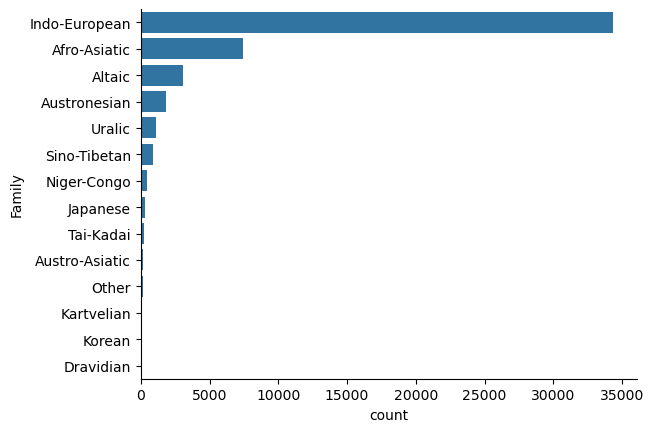

In [127]:
# let's visualize the distribution of language families in the data
# I put the language families on the y-axis, because the names overlap each other if I put them on the x-axis
# countplot counts the rows in each category; ordering by value_counts() puts the most common family at the top
sns.countplot(data = df, y = 'Family', order = df['Family'].value_counts().index)
sns.despine() # I can't help it.

In [128]:
# I wonder if I can find a significant effect between the outcome measure (Speaking)
# and something that has no theoretical justification, like the alphabetical order of the L1.
# add a column with an incrementing value based on the alphabetical order of L1

# Create a new column 'L1_Order' that assigns a unique integer to each unique value in the 'L1' column 
# based on alphabetical order
df['L1_Order'] = df.groupby('L1').ngroup()

# Linear regression with pingouin, where we predict 'Speaking' from 'L1_Order'
pg.linear_regression(df['L1_Order'], df['Speaking'])

,names,coef,se,T,pval,r2,adj_r2,CI[2.5%],CI[97.5%]
0,Intercept,522.900955,0.326101,1603.495262,0.000000e+00,0.007068,0.007049,522.261794,523.540116
1,L1_Order,-0.159928,0.008457,-18.909996,1.784077e-79,0.007068,0.007049,-0.176505,-0.143352


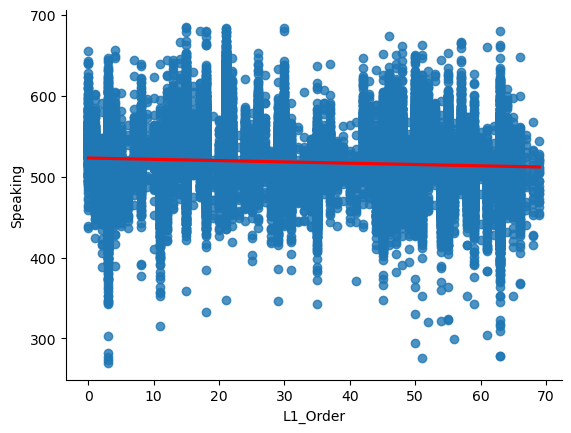

In [129]:

# Plot the points and the regression line
# Make the regression line red, so it can be seen in the sea of blue points
sns.regplot(data = df, x = 'L1_Order', y = 'Speaking', line_kws={"color": "red"})
sns.despine() # It looks better. It just does.


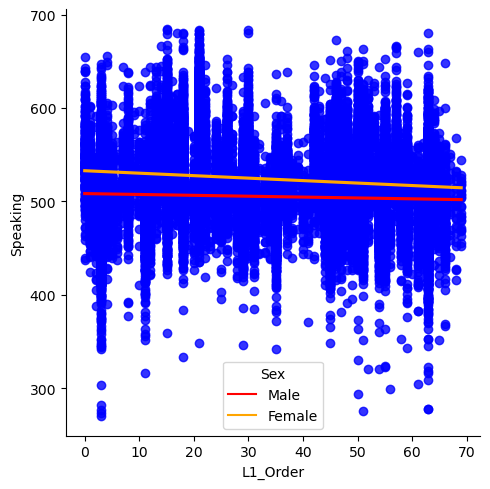

In [130]:
# I want to have two lines: one for male participants and one for female participants.
# This also seems like something that should have nothing to do with what letter the L1 start with.

# Make a scatterplot with a regression line for each sex, 
# make the points blue, the male line red, and the female line orange.
# I didn't write this code all at once; I started with a replot, then realized I needed lmplot to show the two lines
# then added the different colors, then realized that the built-in legend was not showing what I wanted,
# so I added the bottom part with the custom legend. Then I had two legends, and had to set legend=False in the lmplot call to get rid of the built-in legend.
# so that I was left with legend I wanted. I also needed to import Line2D from matplotlib.lines to make the custom legend.

g = sns.lmplot(
    data=df,
    x='L1_Order',
    y='Speaking',
    hue='Sex',
    palette={'Male': 'red', 'Female': 'orange'},
    scatter_kws={'color': 'blue'},
    legend=False
)

from matplotlib.lines import Line2D

g.ax.legend(
    handles=[
        Line2D([0], [0], color='red', label='Male'),
        Line2D([0], [0], color='orange', label='Female')
    ],
    title='Sex'
)


In [131]:
# Here I first tried to do a linear regression with pingouin, but it didn't work because the 'Sex' column is 
# not numeric. So I created a new column 'Sex_numeric' that maps 'Male' to 0 and 'Female' to 1, 
# and then did the linear regression with pingouin. The error message gave no indication (at least to m)
# that the problem was with the 'Sex' column being non-numeric, but with a little googling, I figured it out.
df['Sex_numeric'] = df['Sex'].map({'Male': 0, 'Female': 1})             # Make a new column with numeric values for 'Sex'
pg.linear_regression(df[['L1_Order', 'Sex_numeric']], df['Speaking'])   # Multiple linear regression, with a list of predictors and a single outcome.

,names,coef,se,T,pval,r2,adj_r2,CI[2.5%],CI[97.5%]
0,Intercept,511.434685,0.380052,1345.698235,0.000000e+00,0.062747,0.06271,510.689780,512.179591
1,L1_Order,-0.193900,0.008240,-23.530550,9.081447e-122,0.062747,0.06271,-0.210052,-0.177749
2,Sex_numeric,18.983400,0.347510,54.626916,0.000000e+00,0.062747,0.06271,18.302276,19.664524


From this I draw two lessons:
1. With a large N, even minuscule effects can be statistically significant
2. Just because a relationship is statistically significant doesn't mean it is in any way important, interesting, or theoretically grounded. [Spurious correlations](https://www.tylervigen.com/spurious-correlations) are all around us!

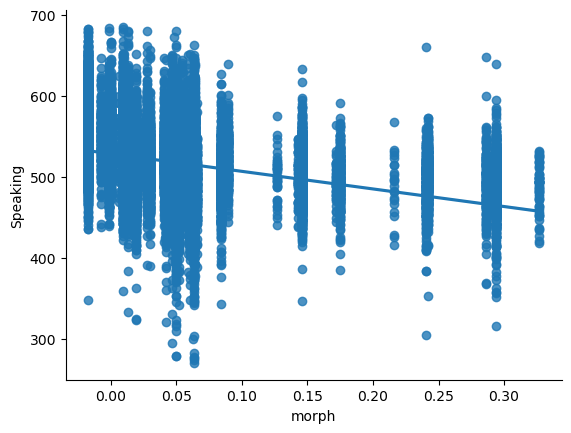

In [132]:
# One last model, with a predictor that has a stronger theoretical justification.
sns.regplot(x='morph', y='Speaking', data=df)
sns.despine()

In [133]:
# Every learner with the same L1 has the same value for morph (and lex, new_feat, new_sounds),
# so the 50,000 rows are not independent observations of the predictor: there are 50,000 participants,
# but nearly so many L1s. If we ignore this and treat them as if they were independent observations,
# the p-values get way too small. I have fixed this by aggregating: one row per L1, with the mean Speaking score
# for each L1.
df_L1 = df.groupby('L1').agg(
    Speaking = ('Speaking', 'mean'), # Mean Speaking score for each L1
    morph = ('morph', 'first'),      # First morph score for each L1 (they will all be the same, so I just took the first)
    n = ('Speaking', 'size')         # Number of observations for each L1
).reset_index().dropna()

print('Number of L1s with a morph score:', len(df_L1))
df_L1.head()

Number of L1s with a morph score: 56


,L1,Speaking,morph,n
1,Albanian,510.520833,0.0412,288
2,Amharic,490.362319,0.0657,138
3,Arabic,498.926438,0.0638,5927
4,Armenian,512.161600,0.0298,625
7,Bosnian,527.474747,0.0638,99


In [134]:
# Now each point is one L1, so the regression compares languages rather than individual learners
res = pg.linear_regression(df_L1['morph'], df_L1['Speaking'])
res

,names,coef,se,T,pval,r2,adj_r2,CI[2.5%],CI[97.5%]
0,Intercept,525.796320,2.808579,187.210771,1.215539e-77,0.406584,0.395595,520.165457,531.427183
1,morph,-153.797483,25.284656,-6.082641,1.256545e-07,0.406584,0.395595,-204.490167,-103.104799


In [135]:
# In the figure below, I want to show the r2 and p-value in the figure. I can find these in the
# output of the model, which I saved in res in the cell above.
# I can see that res['r2'] is a pandas.core.series.Series variable (what a name!) with two parts. Since they are
# the same, I can take either one to use in my figure below. Since there are different p-values (although very close!)
# for Intercept and morph, I'll take the one for morph, which is what I am interested in.
print(list(res))
print(res['r2'])
print(type(res['r2']))
print(res['pval'])

['names', 'coef', 'se', 'T', 'pval', 'r2', 'adj_r2', 'CI[2.5%]', 'CI[97.5%]']
0    0.406584
1    0.406584
Name: r2, dtype: float64
<class 'pandas.core.series.Series'>
0    1.215539e-77
1    1.256545e-07
Name: pval, dtype: float64


In [136]:
# I don't need to set these as separate variables. I could just call them directly in the ax.text function below,
# but I think it can be nice to keep things clear and easy to read.
rsquared = res['r2'][1]
pvalue = res['pval'][1]

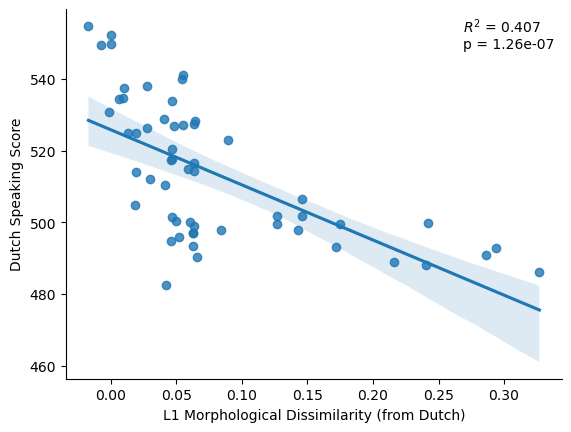

In [137]:
ax = sns.regplot(x='morph', y='Speaking', data=df_L1)
ax.set(xlabel='L1 Morphological Dissimilarity (from Dutch)', ylabel='Dutch Speaking Score')


ax.text(
    0.80, 0.98,                                     # horizontal and vertical points to place the text
    f'$R^2$ = {rsquared:.3g}\np = {pvalue:.3g}',    # the text to add (r2 and p-value) (and round to three significant digits)
    transform=ax.transAxes,                         # read the axes coordinates with 0,0 in the lower left corner (instead of data values)
    ha='left',                                      # pins the left edge of the text to the horizontal anchor (0.80), so lines are left-aligned
    va='top'                                        # pins the top of the text to the vertical anchor (0.98)
)
sns.despine()